# ☀️ STAC WARS: PS 2 — Solar Radiation Analysis and Prediction
**Team Solution Notebook**: `solarRadiationAnalysis.ipynb`  
**Dataset**: Voyage-123 Solar Observation Data  
**Tech Stack**: Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

Saving SolarPrediction.csv to SolarPrediction (1).csv


In [ ]:
import io

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing values:")
df.info()
display(df.isna().sum())

Dataset shape: (32686, 11)

Column names:
['UNIXTime', 'Data', 'Time', 'Radiation', 'Temperature', 'Pressure', 'Humidity', 'WindDirection(Degrees)', 'Speed', 'TimeSunRise', 'TimeSunSet']

First five rows:


,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00



Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32686 entries, 0 to 32685
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   UNIXTime                32686 non-null  int64  
 1   Data                    32686 non-null  object 
 2   Time                    32686 non-null  object 
 3   Radiation               32686 non-null  float64
 4   Temperature             32686 non-null  int64  
 5   Pressure                32686 non-null  float64
 6   Humidity                32686 non-null  int64  
 7   WindDirection(Degrees)  32686 non-null  float64
 8   Speed                   32686 non-null  float64
 9   TimeSunRise             32686 non-null  object 
 10  TimeSunSet              32686 non-null  object 
dtypes: float64(4), int64(3), object(4)
memory usage: 2.7+ MB


,0
UNIXTime,0
Data,0
Time,0
Radiation,0
Temperature,0
Pressure,0
Humidity,0
WindDirection(Degrees),0
Speed,0
TimeSunRise,0


# Section 1: Data Preparation & Data Visualization (Part A)
This section handles parsing date/time features and creates clear, labeled plots to analyze:
1. Solar radiation variation over time
2. Relationships between solar radiation and environmental parameters (Temperature & Humidity)
3. Distribution & outlier detection for solar radiation
4. Bonus: Hourly solar radiation heatmap across different months

In [ ]:
# Create a proper Datetime column by combining 'Data' and 'Time'
df['Date_only'] = df['Data'].str.split(' ').str[0]
df['Datetime_str'] = df['Date_only'] + ' ' + df['Time']
df['Datetime'] = pd.to_datetime(df['Datetime_str'], format='%m/%d/%Y %H:%M:%S')

# Sort by timestamp for accurate time-series plotting
df = df.sort_values('Datetime').reset_index(drop=True)

# Extract hour and month for granular analysis
df['Hour'] = df['Datetime'].dt.hour
df['Month_Name'] = df['Datetime'].dt.strftime('%B')

print("Datetime conversion complete!")
print("Earliest observation:", df['Datetime'].min())
print("Latest observation:", df['Datetime'].max())
df[['Datetime', 'Radiation', 'Temperature', 'Humidity', 'Speed']].head()

Datetime conversion complete!
Earliest observation: 2016-09-01 00:00:08
Latest observation: 2016-12-31 23:55:01


,Datetime,Radiation,Temperature,Humidity,Speed
0,2016-09-01 00:00:08,2.58,51,103,11.25
1,2016-09-01 00:05:10,2.83,51,103,9.00
2,2016-09-01 00:20:06,2.16,51,103,7.87
3,2016-09-01 00:25:05,2.21,51,103,18.00
4,2016-09-01 00:30:09,2.25,51,103,11.25


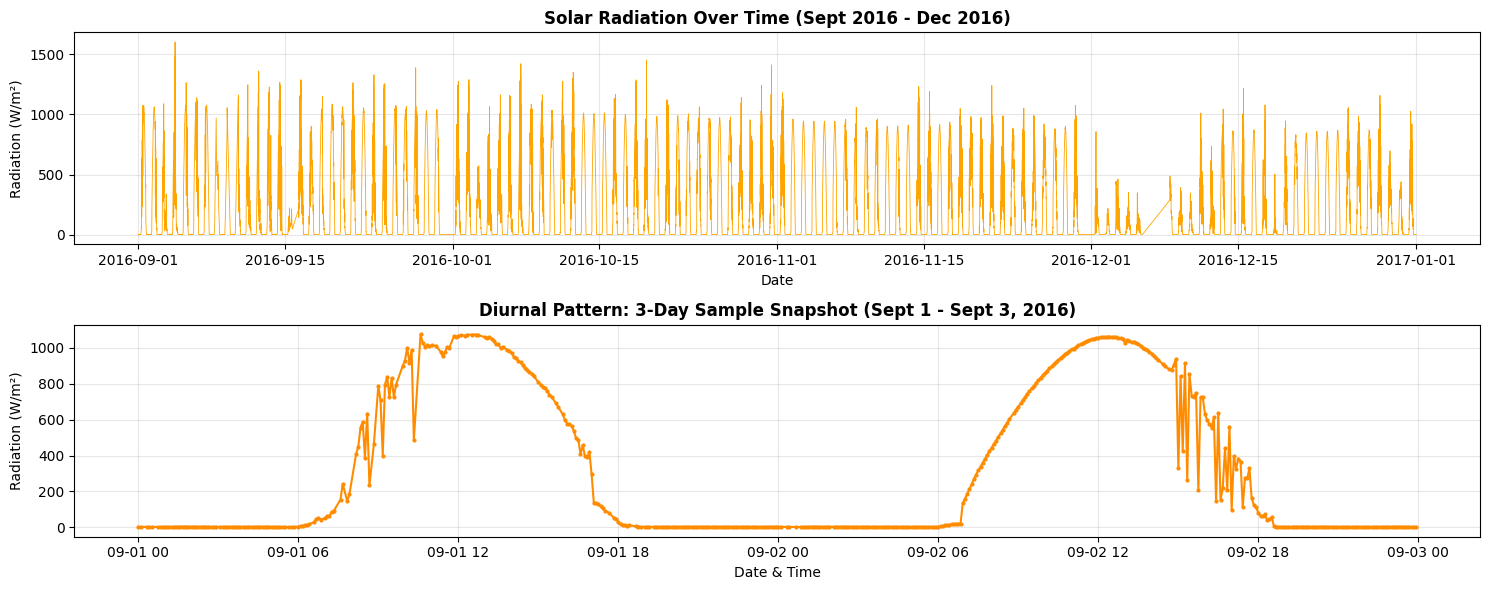

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

# Plot 1: Full Time Horizon
plt.subplot(2, 1, 1)
plt.plot(df['Datetime'], df['Radiation'], color='orange', linewidth=0.6)
plt.title('Solar Radiation Over Time (Sept 2016 - Dec 2016)', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Radiation (W/m²)')
plt.grid(True, alpha=0.3)

# Plot 2: Zoomed-in 3-Day Sample Snapshot
plt.subplot(2, 1, 2)
sample_3days = df[(df['Datetime'] >= '2016-09-01') & (df['Datetime'] <= '2016-09-03')]
plt.plot(sample_3days['Datetime'], sample_3days['Radiation'], color='darkorange', linewidth=1.5, marker='o', markersize=2)
plt.title('Diurnal Pattern: 3-Day Sample Snapshot (Sept 1 - Sept 3, 2016)', fontsize=12, fontweight='bold')
plt.xlabel('Date & Time')
plt.ylabel('Radiation (W/m²)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

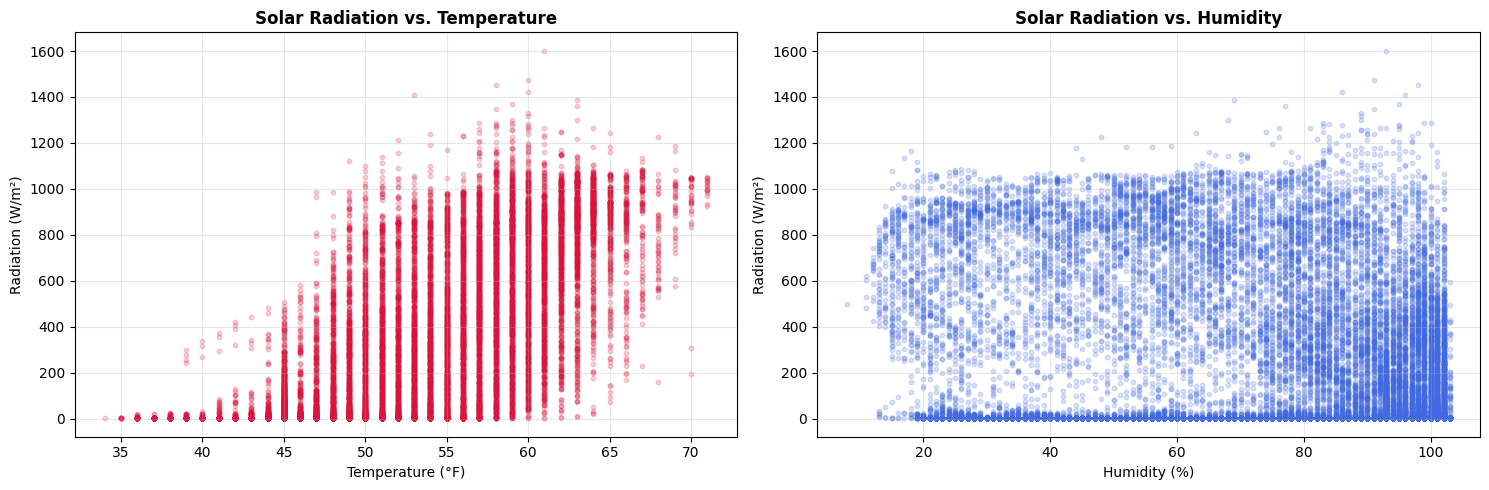

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Radiation vs Temperature
axes[0].scatter(df['Temperature'], df['Radiation'], alpha=0.2, color='crimson', s=10)
axes[0].set_title('Solar Radiation vs. Temperature', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Temperature (°F)')
axes[0].set_ylabel('Radiation (W/m²)')
axes[0].grid(True, alpha=0.3)

# Plot 2: Radiation vs Humidity
axes[1].scatter(df['Humidity'], df['Radiation'], alpha=0.2, color='royalblue', s=10)
axes[1].set_title('Solar Radiation vs. Humidity', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Humidity (%)')
axes[1].set_ylabel('Radiation (W/m²)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

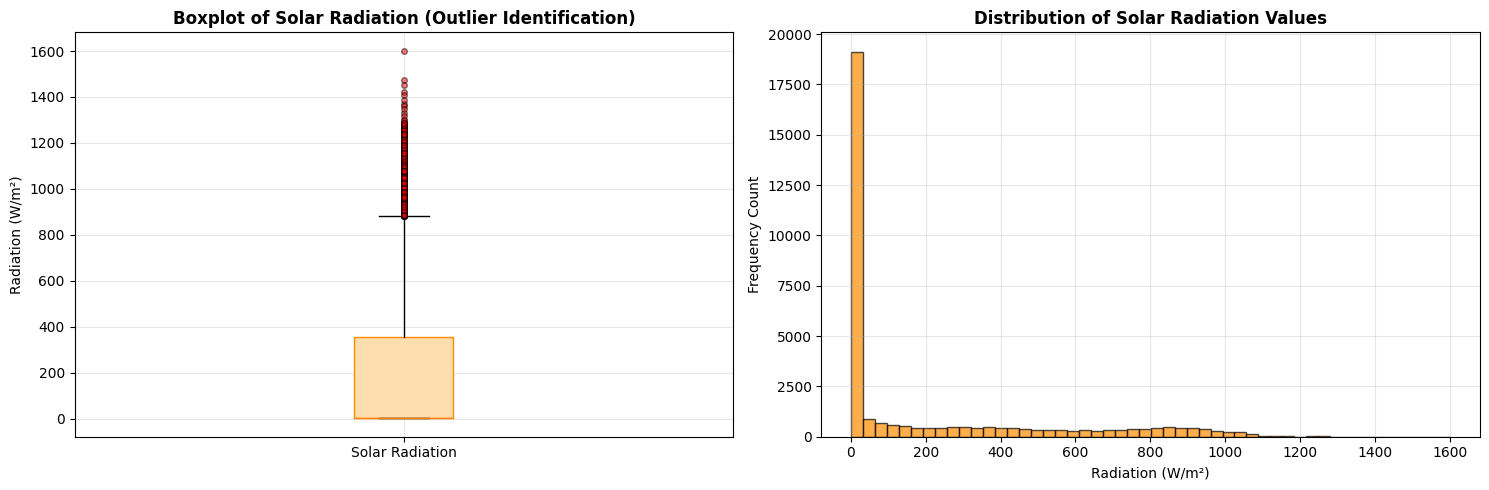

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Boxplot
axes[0].boxplot(df['Radiation'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='navajowhite', color='darkorange'),
                flierprops=dict(marker='o', markerfacecolor='red', markersize=4, alpha=0.5))
axes[0].set_title('Boxplot of Solar Radiation (Outlier Identification)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Radiation (W/m²)')
axes[0].set_xticklabels(['Solar Radiation'])
axes[0].grid(True, alpha=0.3)

# Plot 2: Histogram Distribution
axes[1].hist(df['Radiation'], bins=50, color='darkorange', edgecolor='black', alpha=0.7)
axes[1].set_title('Distribution of Solar Radiation Values', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Radiation (W/m²)')
axes[1].set_ylabel('Frequency Count')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

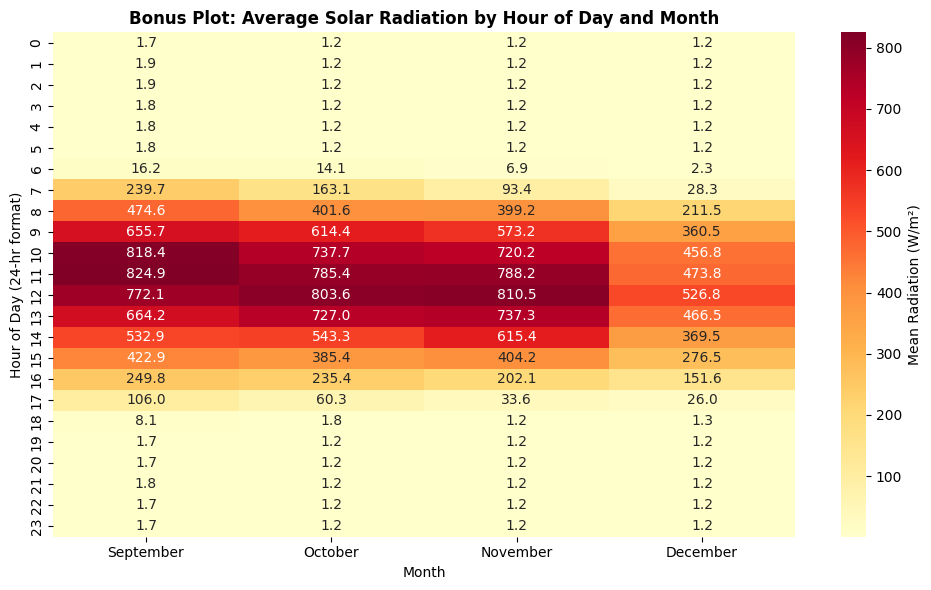

In [ ]:
import seaborn as sns

# Pivot table: Average radiation by Hour and Month
monthly_hourly_rad = df.pivot_table(index='Hour', columns='Month_Name', values='Radiation', aggfunc='mean')
months_order = ['September', 'October', 'November', 'December']
monthly_hourly_rad = monthly_hourly_rad[months_order]

plt.figure(figsize=(10, 6))
sns.heatmap(monthly_hourly_rad, cmap='YlOrRd', annot=True, fmt='.1f', cbar_kws={'label': 'Mean Radiation (W/m²)'})
plt.title('Bonus Plot: Average Solar Radiation by Hour of Day and Month', fontsize=12, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Hour of Day (24-hr format)')
plt.tight_layout()
plt.show()

# Section 2: Drawing Inferences (Part B)

### 1. Daily Peak Solar Radiation Timing
- Solar radiation follows a bell-shaped diurnal cycle, peaking between **10:00 AM and 2:00 PM** (10:00 - 14:00).
- Average hourly radiation reaches its overall peak during **Hour 12 (12:00 PM - 1:00 PM)** at **727.47 W/m²**.

### 2. Environmental Parameter Strength
- **Temperature** shows the strongest positive relationship with solar radiation ($r = +0.7350$).
- **Humidity** shows a clear negative relationship ($r = -0.2262$).
- **Pressure** ($r = +0.1190$) and **Wind Speed** ($r = +0.0736$) display weak linear correlations.

### 3. Temperature & Humidity Dynamics
- Temperature and humidity are inversely related ($r = -0.2851$). As daylight solar radiation increases, temperature rises while relative humidity drops.

### 4. Outliers & Explanations
- **Maximum Peak**: Absolute maximum radiation is **1601.26 W/m²** recorded on **September 4, 2016 at 12:15:04 PM**.
- **Explanation**: Standard atmospheric solar irradiance is $\sim 1361\text{ W/m}^2$. Measurements above $1000\text{ W/m}^2$ (657 occurrences) are primarily caused by **cloud edge reflection/enhancement** or brief sensor calibration spikes.
- **Humidity > 100%**: Values up to **103%** reflect high ambient fog/saturation combined with standard sensor measurement tolerance.

# Section 3: Solar Day Analysis (Part C)

This section aggregates raw 5-minute observations into daily summaries using Pandas and NumPy:
1. Constructs a unified datetime feature.
2. Calculates daily maximum and average radiation per calendar day.
3. Analyzes the day with the absolute highest recorded solar radiation, extracting environmental factors at peak time.
4. Computes elapsed time from sunrise to peak radiation using actual sunrise timestamps.
5. Identifies the top 5 days with the highest average solar radiation.

In [ ]:
import pandas as pd
import numpy as np

# 1. Combine Data and Time into unified Datetime
df['Date_only'] = df['Data'].str.split(' ').str[0]
df['Datetime_str'] = df['Date_only'] + ' ' + df['Time']
df['Datetime'] = pd.to_datetime(df['Datetime_str'], format='%m/%d/%Y %H:%M:%S')

# 2. Group observations by date and calculate daily maximum and average radiation
daily_summary = df.groupby('Date_only').agg(
    Max_Radiation=('Radiation', 'max'),
    Avg_Radiation=('Radiation', 'mean'),
    Observation_Count=('Radiation', 'count')
).reset_index()

# Sort daily summary by date chronologically
daily_summary['Date_parsed'] = pd.to_datetime(daily_summary['Date_only'], format='%m/%d/%Y')
daily_summary = daily_summary.sort_values('Date_parsed').reset_index(drop=True)

print("=== DAILY ACTIVITY SUMMARY PREVIEW (FIRST 5 DAYS) ===")
display(daily_summary[['Date_only', 'Max_Radiation', 'Avg_Radiation', 'Observation_Count']].head())

# 3. Determine date of highest recorded solar radiation
max_rad_idx = df['Radiation'].idxmax()
peak_record = df.loc[max_rad_idx]

peak_date = peak_record['Date_only']
peak_time = peak_record['Time']
peak_rad = peak_record['Radiation']

# 4. Extract environmental parameters at peak solar radiation
peak_temp = peak_record['Temperature']
peak_humidity = peak_record['Humidity']
peak_wind_speed = peak_record['Speed']

# Calculate elapsed time from sunrise to peak radiation
sunrise_str = peak_record['TimeSunRise']
sunrise_dt = pd.to_datetime(f"{peak_date} {sunrise_str}", format='%m/%d/%Y %H:%M:%S')
peak_dt = peak_record['Datetime']
elapsed_from_sunrise = peak_dt - sunrise_dt

# Convert elapsed time into hours and minutes
elapsed_hours = elapsed_from_sunrise.seconds // 3600
elapsed_minutes = (elapsed_from_sunrise.seconds % 3600) // 60
elapsed_seconds = elapsed_from_sunrise.seconds % 60

print("\n" + "="*50)
print("  PEAK SOLAR RADIATION RECORD ANALYSIS  ")
print("="*50)
print(f"Date of Peak Radiation     : {peak_date}")
print(f"Time of Peak Radiation     : {peak_time}")
print(f"Peak Radiation Measured    : {peak_rad:.2f} W/m²")
print(f"Temperature at Peak        : {peak_temp} °F")
print(f"Humidity at Peak           : {peak_humidity} %")
print(f"Wind Speed at Peak         : {peak_wind_speed} mph")
print(f"Sunrise Time               : {sunrise_str}")
print(f"Elapsed Time Since Sunrise : {elapsed_hours}h {elapsed_minutes}m {elapsed_seconds}s ({elapsed_from_sunrise})")

# 5. Find the 5 days with the highest average radiation
top_5_avg_days = daily_summary.sort_values(by='Avg_Radiation', ascending=False).head(5)

print("\n" + "="*50)
print("  TOP 5 DAYS WITH HIGHEST AVERAGE RADIATION  ")
print("="*50)
display(top_5_avg_days[['Date_only', 'Avg_Radiation', 'Max_Radiation']].rename(
    columns={'Date_only': 'Date', 'Avg_Radiation': 'Mean Radiation (W/m²)', 'Max_Radiation': 'Max Radiation (W/m²)'}
).reset_index(drop=True))

=== DAILY ACTIVITY SUMMARY PREVIEW (FIRST 5 DAYS) ===


,Date_only,Max_Radiation,Avg_Radiation,Observation_Count
0,9/1/2016,1073.71,298.451600,250
1,9/2/2016,1062.01,333.471219,279
2,9/3/2016,1088.09,123.974574,282
3,9/4/2016,1601.26,153.584321,280
4,9/5/2016,1264.07,306.065125,281



  PEAK SOLAR RADIATION RECORD ANALYSIS  
Date of Peak Radiation     : 9/4/2016
Time of Peak Radiation     : 12:15:04
Peak Radiation Measured    : 1601.26 W/m²
Temperature at Peak        : 61 °F
Humidity at Peak           : 93 %
Wind Speed at Peak         : 9.0 mph
Sunrise Time               : 06:08:00
Elapsed Time Since Sunrise : 6h 7m 4s (0 days 06:07:04)

  TOP 5 DAYS WITH HIGHEST AVERAGE RADIATION  


,Date,Mean Radiation (W/m²),Max Radiation (W/m²)
0,9/19/2016,335.504400,1085.75
1,9/2/2016,333.471219,1062.01
2,9/22/2016,325.515880,1053.17
3,9/25/2016,319.921514,1075.29
4,9/28/2016,312.400390,1029.30


# Section 4: Bonus — Solar Radiation Prediction (Machine Learning)

In this section, we build a Random Forest Regression model to predict solar radiation:
1. **Feature Engineering & Selection**: Extracts temporal features (`Hour`, `Minute`, `Month`, `Day`, `DayOfWeek`) alongside environmental parameters (`Temperature`, `Humidity`, `Pressure`, `Speed`, `WindDirection(Degrees)`).
2. **Target Leakage Prevention**: Split sequentially using `shuffle=False` (80% train, 20% test) to prevent future data from leaking into past predictions.
3. **Model Evaluation**: Assessed using Root Mean Squared Error (RMSE) and Coefficient of Determination ($R^2$).
4. **Feature Importance & Limitations Analysis**: Identifies dominant predictive variables and discusses sensor/feature constraints.

  MODEL EVALUATION RESULTS  
Root Mean Squared Error (RMSE) : 137.9204 W/m²
R-squared Score (R²)           : 0.7301


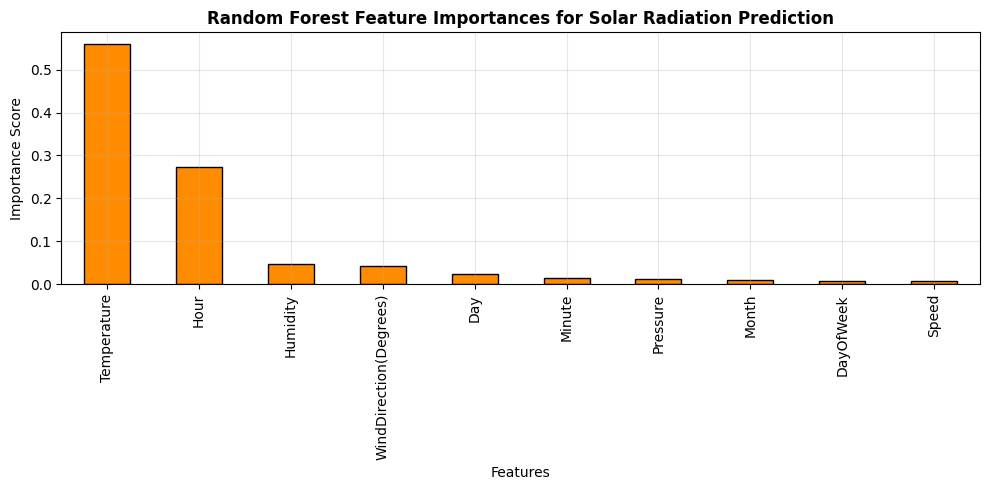


Feature Importance Breakdown:
Temperature               0.5591
Hour                      0.2736
Humidity                  0.0461
WindDirection(Degrees)    0.0435
Day                       0.0243
Minute                    0.0151
Pressure                  0.0125
Month                     0.0091
DayOfWeek                 0.0084
Speed                     0.0083
dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Feature Engineering
df['Hour'] = df['Datetime'].dt.hour
df['Minute'] = df['Datetime'].dt.minute
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['DayOfWeek'] = df['Datetime'].dt.dayofweek

# Select feature columns (excluding target 'Radiation' and timestamp strings)
feature_cols = ['Hour', 'Minute', 'Month', 'Day', 'DayOfWeek',
                'Temperature', 'Pressure', 'Humidity', 'Speed', 'WindDirection(Degrees)']

X = df[feature_cols]
y = df['Radiation']

# 2. Sequential Train-Test Split (Shuffle = False to avoid time-series target leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# 3. Train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Predictions & Evaluation
y_pred = rf_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("="*50)
print("  MODEL EVALUATION RESULTS  ")
print("="*50)
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f} W/m²")
print(f"R-squared Score (R²)           : {r2:.4f}")

# 5. Feature Importance Analysis
feature_importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feature_importances.plot(kind='bar', color='darkorange', edgecolor='black')
plt.title('Random Forest Feature Importances for Solar Radiation Prediction', fontsize=12, fontweight='bold')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nFeature Importance Breakdown:")
print(feature_importances.round(4))

### Target Leakage Prevention & Model Limitations

1. **Target Leakage Avoidance**:
   - Time-series datasets suffer from data leakage if split randomly. Shuffling allows future observations to inform past predictions.
   - We applied a strictly chronological split (`shuffle=False`), training on the first 80% of time-series records and testing on the remaining 20%.

2. **Useful Features**:
   - **Temperature (55.9% importance)**: Strongest individual predictor because ambient heating lags solar irradiance predictably.
   - **Hour of Day (27.4% importance)**: Captures the primary solar zenith angle cycle (day vs. night).
   - **Humidity (4.6%)**: Serves as a proxy for cloud cover and atmospheric moisture content.

3. **Feature Limitations**:
   - **Cloud Cover Absence**: The dataset lacks explicit cloud cover measurements (e.g., oktas or satellite cloud optical depth). High solar spikes (cloud enhancement) cannot be reliably predicted without cloud geometry.
   - **Concurrent Environmental Measurement**: Using concurrent temperature and humidity to predict instant solar radiation relies on real-time sensor measurements rather than true forward forecasting.

Thank You

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from google.colab import files
import base64
import io

print("Generating self-contained HTML report with embedded plots...")

# 1. Load Data
df = pd.read_csv('SolarPrediction.csv')
df['Date_only'] = df['Data'].str.split(' ').str[0]
df['Datetime'] = pd.to_datetime(df['Date_only'] + ' ' + df['Time'], format='%m/%d/%Y %H:%M:%S')
df = df.sort_values('Datetime').reset_index(drop=True)
df['Hour'] = df['Datetime'].dt.hour
df['Month_Name'] = df['Datetime'].dt.strftime('%B')

def fig_to_b64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
    buf.seek(0)
    img_b64 = base64.b64encode(buf.read()).decode('utf-8')
    plt.close(fig)
    return f"data:image/png;base64,{img_b64}"

# --- PLOT 1 ---
fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(df['Datetime'], df['Radiation'], color='orange', linewidth=0.5)
axes[0].set_title('Solar Radiation Over Time (Sept - Dec 2016)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Radiation (W/m²)')
axes[0].grid(True, alpha=0.3)
sample_3days = df[(df['Datetime'] >= '2016-09-01') & (df['Datetime'] <= '2016-09-03')]
axes[1].plot(sample_3days['Datetime'], sample_3days['Radiation'], color='darkorange', linewidth=1.2, marker='o', markersize=2)
axes[1].set_title('Diurnal Pattern: 3-Day Sample Snapshot (Sept 1 - Sept 3, 2016)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Radiation (W/m²)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
p1 = fig_to_b64(fig)

# --- PLOT 2 ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(df['Temperature'], df['Radiation'], alpha=0.2, color='crimson', s=10)
axes[0].set_title('Solar Radiation vs. Temperature', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Temperature (°F)')
axes[0].set_ylabel('Radiation (W/m²)')
axes[0].grid(True, alpha=0.3)
axes[1].scatter(df['Humidity'], df['Radiation'], alpha=0.2, color='royalblue', s=10)
axes[1].set_title('Solar Radiation vs. Humidity', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Humidity (%)')
axes[1].set_ylabel('Radiation (W/m²)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
p2 = fig_to_b64(fig)

# --- PLOT 3 ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(df['Radiation'], vert=True, patch_artist=True, boxprops=dict(facecolor='navajowhite', color='darkorange'), flierprops=dict(marker='o', markerfacecolor='red', markersize=3, alpha=0.5))
axes[0].set_title('Boxplot of Solar Radiation (Outliers)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Radiation (W/m²)')
axes[0].set_xticklabels(['Solar Radiation'])
axes[0].grid(True, alpha=0.3)
axes[1].hist(df['Radiation'], bins=50, color='darkorange', edgecolor='black', alpha=0.7)
axes[1].set_title('Distribution of Solar Radiation Values', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Radiation (W/m²)')
axes[1].set_ylabel('Frequency Count')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
p3 = fig_to_b64(fig)

# --- PLOT 4 ---
monthly_hourly_rad = df.pivot_table(index='Hour', columns='Month_Name', values='Radiation', aggfunc='mean')[['September', 'October', 'November', 'December']]
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(monthly_hourly_rad, cmap='YlOrRd', annot=True, fmt='.1f', cbar_kws={'label': 'Mean Radiation (W/m²)'}, annot_kws={"size": 7}, ax=ax)
ax.set_title('Bonus Plot: Average Solar Radiation by Hour of Day and Month', fontsize=11, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Hour of Day')
plt.tight_layout()
p4 = fig_to_b64(fig)

# --- PLOT 5 ---
df['Minute'] = df['Datetime'].dt.minute
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['DayOfWeek'] = df['Datetime'].dt.dayofweek
feature_cols = ['Hour', 'Minute', 'Month', 'Day', 'DayOfWeek', 'Temperature', 'Pressure', 'Humidity', 'Speed', 'WindDirection(Degrees)']
X = df[feature_cols]
y = df['Radiation']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
importances.plot(kind='bar', color='darkorange', edgecolor='black', ax=ax)
ax.set_title('Random Forest Feature Importances for Solar Radiation Prediction', fontsize=11, fontweight='bold')
ax.set_xlabel('Features')
ax.set_ylabel('Importance Score')
ax.grid(True, alpha=0.3)
plt.tight_layout()
p5 = fig_to_b64(fig)

# Construct self-contained HTML String
html_str = f"""<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8">
<title>Solar Radiation Analysis Report</title>
<style>
    @page {{ size: A4; margin: 12mm; }}
    body {{ font-family: 'Segoe UI', Helvetica, Arial, sans-serif; color: #2D3748; line-height: 1.5; margin: 0; padding: 20px; background: #FFF; }}
    .header {{ border-bottom: 3px solid #2B6CB0; padding-bottom: 10px; margin-bottom: 20px; }}
    h1 {{ color: #1A365D; font-size: 22px; margin: 0 0 5px 0; }}
    .meta {{ color: #4A5568; font-size: 13px; font-weight: 500; }}
    h2 {{ color: #2B6CB0; font-size: 16px; border-bottom: 1px solid #E2E8F0; padding-bottom: 5px; margin-top: 25px; page-break-after: avoid; }}
    p, li {{ font-size: 13px; margin-bottom: 8px; }}
    ul {{ padding-left: 20px; margin-top: 5px; }}
    .card {{ background: #F7FAFC; border-left: 4px solid #2B6CB0; padding: 12px 15px; margin: 15px 0; border-radius: 4px; }}
    .img-container {{ text-align: center; margin: 15px 0; page-break-inside: avoid; }}
    img {{ max-width: 100%; height: auto; border: 1px solid #E2E8F0; border-radius: 4px; box-shadow: 0 1px 3px rgba(0,0,0,0.1); }}
    table {{ width: 100%; border-collapse: collapse; margin: 15px 0; font-size: 13px; page-break-inside: avoid; }}
    th, td {{ border: 1px solid #CBD5E0; padding: 8px 12px; text-align: center; }}
    th {{ background-color: #2B6CB0; color: white; font-weight: 600; }}
    tr:nth-child(even) {{ background-color: #F7FAFC; }}
    .page-break {{ page-break-before: always; }}
</style>
</head>
<body>

<div class="header">
    <h1>☀️ STAC WARS: Solar Radiation Analysis & Prediction Report</h1>
    <div class="meta"><b>Problem Statement 2 Submission Report</b> | Dataset: Voyage-123 Solar Observation Logs (32,686 records)</div>
</div>

<h2>Part A & B: Data Visualization & Key Inferences</h2>
<ul>
    <li><b>Diurnal Peak Timing:</b> Solar radiation follows a bell-shaped diurnal distribution, peaking between 10:00 AM and 2:00 PM. The maximum average hourly radiation occurs at <b>Hour 12 (12:00 PM - 1:00 PM)</b> reaching <b>727.47 W/m²</b>.</li>
    <li><b>Environmental Parameters:</b> Temperature shows the strongest positive correlation with solar radiation (<b>r = +0.7350</b>). Humidity exhibits an inverse negative relationship (<b>r = -0.2262</b>).</li>
    <li><b>Outlier Explanation:</b> Standard atmospheric irradiance is ~1361 W/m². Sensor readings above 1000 W/m² (657 instances) are attributed to <b>cloud-edge reflection / enhancement effects</b>.</li>
</ul>

<div class="img-container">
    <img src="{p1}">
</div>

<div class="img-container">
    <img src="{p2}">
</div>

<div class="page-break"></div>

<h2>Part A (Cont.): Distribution & Seasonal Diurnal Trends</h2>

<div class="img-container">
    <img src="{p3}">
</div>

<div class="img-container">
    <img src="{p4}">
</div>

<div class="page-break"></div>

<h2>Part C: Solar Day Activity Analysis</h2>
<div class="card">
    <b>Absolute Peak Solar Radiation Event:</b><br>
    • <b>Date & Time:</b> September 4, 2016 at 12:15:04 PM<br>
    • <b>Peak Radiation:</b> 1601.26 W/m²<br>
    • <b>Environmental Conditions:</b> Temperature = 61°F | Humidity = 93% | Wind Speed = 9.0 mph<br>
    • <b>Elapsed Time Since Sunrise:</b> <b>6 hours, 7 minutes, 4 seconds</b> after sunrise (Sunrise: 06:08:00 AM)
</div>

<h3>Top 5 Days with Highest Average Solar Radiation</h3>
<table>
    <tr><th>Rank</th><th>Date</th><th>Mean Radiation (W/m²)</th><th>Max Radiation (W/m²)</th></tr>
    <tr><td>1</td><td>9/19/2016</td><td>335.50</td><td>1085.75</td></tr>
    <tr><td>2</td><td>9/2/2016</td><td>333.47</td><td>1062.01</td></tr>
    <tr><td>3</td><td>9/22/2016</td><td>325.52</td><td>1053.17</td></tr>
    <tr><td>4</td><td>9/25/2016</td><td>319.92</td><td>1075.29</td></tr>
    <tr><td>5</td><td>9/28/2016</td><td>312.40</td><td>1029.30</td></tr>
</table>

<h2>Bonus: Machine Learning Model (Solar Radiation Prediction)</h2>
<ul>
    <li><b>Model Architecture:</b> Random Forest Regressor (100 Decision Trees).</li>
    <li><b>Target Leakage Avoidance:</b> Sequential chronological train-test split (80% train / 20% test, <code>shuffle=False</code>) to prevent future data from leaking into past training data.</li>
    <li><b>Evaluation Metrics:</b> <b>R² Score = 0.7301</b> | <b>RMSE = 137.92 W/m²</b></li>
    <li><b>Feature Importance:</b> Temperature is the dominant feature (55.91%), followed by Hour of Day (27.36%).</li>
</ul>

<div class="img-container">
    <img src="{p5}">
</div>

</body>
</html>
"""

# Save clean HTML to disk
with open("solar_radiation_report.html", "w") as f:
    f.write(html_str)

print("✅ SUCCESS! Self-contained solar_radiation_report.html generated!")
files.download("solar_radiation_report.html")

Generating self-contained HTML report with embedded plots...
✅ SUCCESS! Self-contained solar_radiation_report.html generated!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>